# 05 · Costs and marketing

A rough operating view from the recorded costs, and a direct test of whether campaigns move sales.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from utils import *

lines = load_lines()
orders = load_orders()
years = list(range(2019, 2027))

## 1. Operating view

In [2]:
opex = read("operating_expenses.csv", dates=["expense_date"])
payroll = read("payroll.csv")
campaigns = read("marketing_campaigns.csv", dates=["start_date", "end_date"])
transfers = read("inventory_transfers.csv", dates=["transfer_date"])

opex["FY"] = fiscal_year(opex["expense_date"])
payroll["FY"] = fiscal_year(pd.to_datetime(payroll["pay_month"] + "-01"))
campaigns["FY"] = fiscal_year(campaigns["start_date"])
transfers["FY"] = fiscal_year(transfers["transfer_date"])

pnl = pd.DataFrame({
    "net_sales": lines.groupby("FY")["net_line_EGP"].sum(),
    "gross_margin": lines.groupby("FY")["margin_EGP"].sum(),
    "opex": opex.groupby("FY")["amount_EGP"].sum(),
    "marketing": campaigns.groupby("FY")["spend_EGP"].sum(),
    "payroll": payroll.groupby("FY")["net_paid_EGP"].sum(),
    "transfers": transfers.groupby("FY")["transport_cost_EGP"].sum(),
}).loc[years].fillna(0)
pnl["operating_profit"] = pnl["gross_margin"] - pnl[["opex", "marketing", "payroll", "transfers"]].sum(axis=1)
pnl["op_margin_%"] = pnl["operating_profit"] / pnl["net_sales"] * 100
(pnl / 1e6).round(1).assign(**{"op_margin_%": pnl["op_margin_%"].round(1)})

,net_sales,gross_margin,opex,marketing,payroll,transfers,operating_profit,op_margin_%
FY,,,,,,,,
2019,19.2,7.3,5.9,23.3,0.4,3.4,-25.6,-133.4
2020,24.6,9.4,6.9,24.5,2.0,3.6,-27.6,-112.4
2021,31.0,11.9,7.6,25.3,4.3,3.7,-29.0,-93.5
2022,46.3,17.7,10.2,29.8,7.0,3.6,-33.0,-71.2
2023,74.2,28.4,14.1,30.1,10.2,3.6,-29.6,-40.0
2024,131.0,50.4,21.3,29.0,14.7,3.6,-18.3,-14.0
2025,211.3,81.0,29.5,26.8,15.2,3.8,5.7,2.7
2026,289.2,110.9,38.1,28.9,5.6,3.4,34.9,12.1


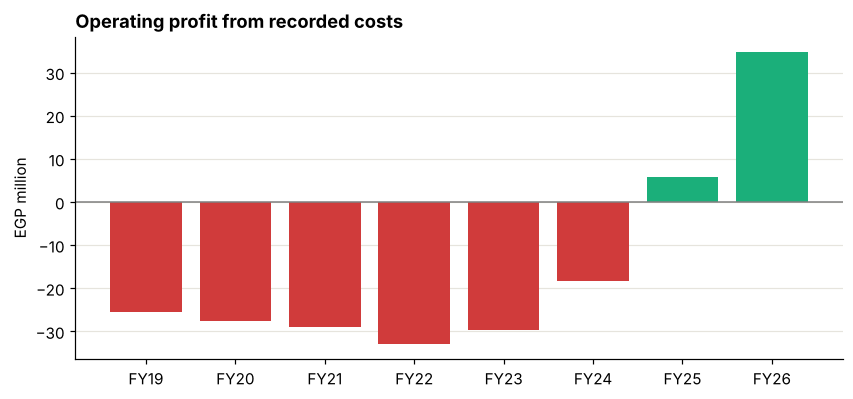

In [3]:
plt.figure(figsize=(9, 3.8))
plt.bar([f"FY{str(y)[2:]}" for y in years], pnl["operating_profit"] / 1e6,
        color=[RED if v < 0 else GREEN for v in pnl["operating_profit"]])
plt.axhline(0, color="gray", lw=1)
plt.ylabel("EGP million")
plt.title("Operating profit from recorded costs")
save("05_operating_profit")
plt.show()

FY26 looks like a 12% operating margin. But costs stay flat in EGP while prices rose 6x,
and FY19 marketing (EGP 23M) was bigger than FY19 sales (EGP 19M), so the trend isn't believable.

In [4]:
employees = read("employees.csv")
implied = employees["salary_base_EGP_2026"].sum() * 12
print(f"Payroll recorded in FY26: {millions(pnl.loc[2026, 'payroll'])} vs implied by staff list: {millions(implied)}")
print(opex.groupby("expense_category")["amount_EGP"].sum().sort_values(ascending=False).map(millions))

Payroll recorded in FY26: 5.6M vs implied by staff list: 91.5M
expense_category
Rent                      23.0M
Utilities                 22.9M
Marketing                 11.8M
Travel                    11.6M
Logistics                 11.3M
Insurance                 11.2M
Maintenance               11.1M
General administration    11.1M
Supplies                  10.9M
IT & software             10.8M
Name: amount_EGP, dtype: str


## 2. Marketing: what campaigns claim

In [5]:
print(f"Spend: {millions(campaigns['spend_EGP'].sum())}")
print(f"Orders claimed by campaigns: {campaigns['orders_attributed'].sum():,}")
print(f"Real orders in the data: {len(orders):,}")

ch = campaigns.groupby("channel").agg(spend=("spend_EGP", "sum"), clicks=("clicks", "sum"),
                                      impressions=("impressions", "sum"), orders=("orders_attributed", "sum"))
ch["ctr_%"] = ch["clicks"] / ch["impressions"] * 100
ch["cost_per_order"] = ch["spend"] / ch["orders"]
ch["share_%"] = ch["spend"] / ch["spend"].sum() * 100
ch[["share_%", "ctr_%", "cost_per_order"]].round(2)

Spend: 219.5M
Orders claimed by campaigns: 24,106,747
Real orders in the data: 540,000


,share_%,ctr_%,cost_per_order
channel,,,
Google Ads,17.21,4.36,9.36
In-store,16.50,4.58,8.42
Influencers,16.12,4.23,9.52
Meta Ads,17.60,4.67,8.39
Outdoor,17.12,4.48,9.98
SMS / CRM,15.45,4.40,9.22


## 3. Marketing: what actually happens to sales

Each campaign targets one governorate. Compare daily sales there during the campaign vs the 28 days before,
then subtract the same change in the other governorates (the median), so seasonality and inflation cancel out.

In [6]:
cust_gov = read("customers.csv")[["customer_id", "governorate_ar"]]
daily = (orders.merge(cust_gov, on="customer_id")
         .pivot_table(index="order_date", columns="governorate_ar", values="net_before_tax_EGP", aggfunc="sum")
         .fillna(0))
running = daily.cumsum()


def total_until(day):
    rows = running.loc[:day]
    return rows.iloc[-1] if len(rows) else running.iloc[0] * 0   # nothing before the data starts


def total_between(start, end):
    return total_until(end) - total_until(start - pd.Timedelta(days=1))


extra_lift = []
for _, c in campaigns.iterrows():
    days = (c["end_date"] - c["start_date"]).days + 1
    during = total_between(c["start_date"], c["end_date"]) / days
    before = total_between(c["start_date"] - pd.Timedelta(days=28), c["start_date"] - pd.Timedelta(days=1)) / 28
    change = during / before.replace(0, np.nan) - 1
    target = c["governorate_ar"]
    if pd.isna(change.get(target)):
        extra_lift.append(np.nan)
        continue
    extra_lift.append(change[target] - change.drop(target).median())

campaigns["extra_lift"] = extra_lift
print(f"Median extra lift: {campaigns['extra_lift'].median():+.1%}")
print(f"Campaigns with positive lift: {(campaigns['extra_lift'] > 0).mean():.0%}")
campaigns.groupby("channel")["extra_lift"].median().map("{:+.1%}".format)

Median extra lift: +0.5%
Campaigns with positive lift: 51%


channel
Google Ads     -0.1%
In-store       -0.5%
Influencers    +1.9%
Meta Ads       +1.5%
Outdoor        -1.5%
SMS / CRM      +0.7%
Name: extra_lift, dtype: str

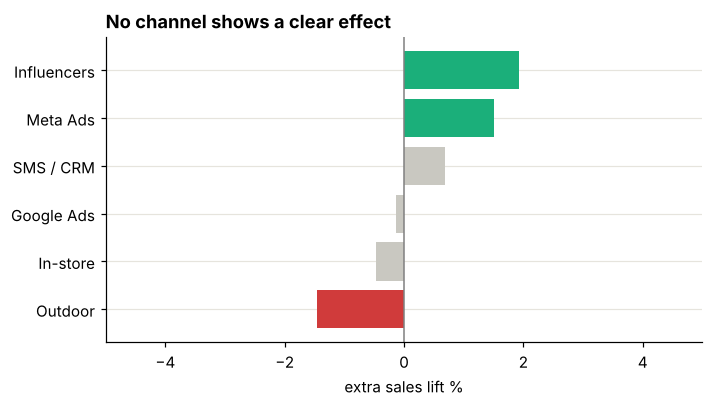

In [7]:
lift = campaigns.groupby("channel")["extra_lift"].median().sort_values() * 100
plt.figure(figsize=(7, 3.6))
plt.barh(lift.index, lift.values, color=[GREEN if v > 1 else RED if v < -1 else GREY for v in lift])
plt.axvline(0, color="gray", lw=1)
plt.xlim(-5, 5)
plt.xlabel("extra sales lift %")
plt.title("No channel shows a clear effect")
save("05_marketing_lift")
plt.show()

**Summary:** recorded costs can't be trusted over time; campaigns claim 45x the real orders and show
no measurable lift. Next step: run campaigns with a holdout governorate before deciding the budget.